# 10 · Quality control: measurements, decisions and the thresholds

This notebook covers the **non-neural** part of the system, the quality analysis that decides whether a photograph is accepted, sent for review, or rejected (for example "too blurry to enhance"), and shows where the thresholds sit on the real measurements. These thresholds are the project's own calibration work: they are chosen from the distribution of the project's photographs, not copied from a model card.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


decisions: {'accepted': 168, 'needs_review': 133, 'rejected': 4, '': 1}
rejection reasons: {'borderline_resolution': 16, 'underexposed': 52, 'borderline_contrast': 22, 'face_validation_required': 103, 'severe_blur': 2, 'overall_score_below_acceptance': 5, 'overexposed': 2, 'borderline_blur': 14, 'severe_overexposure': 1}


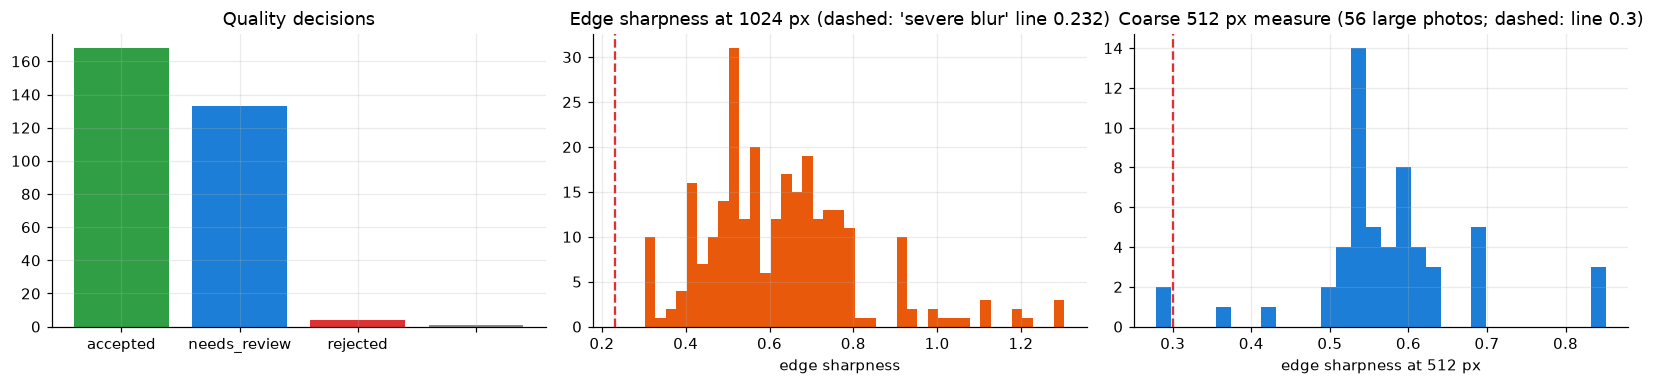

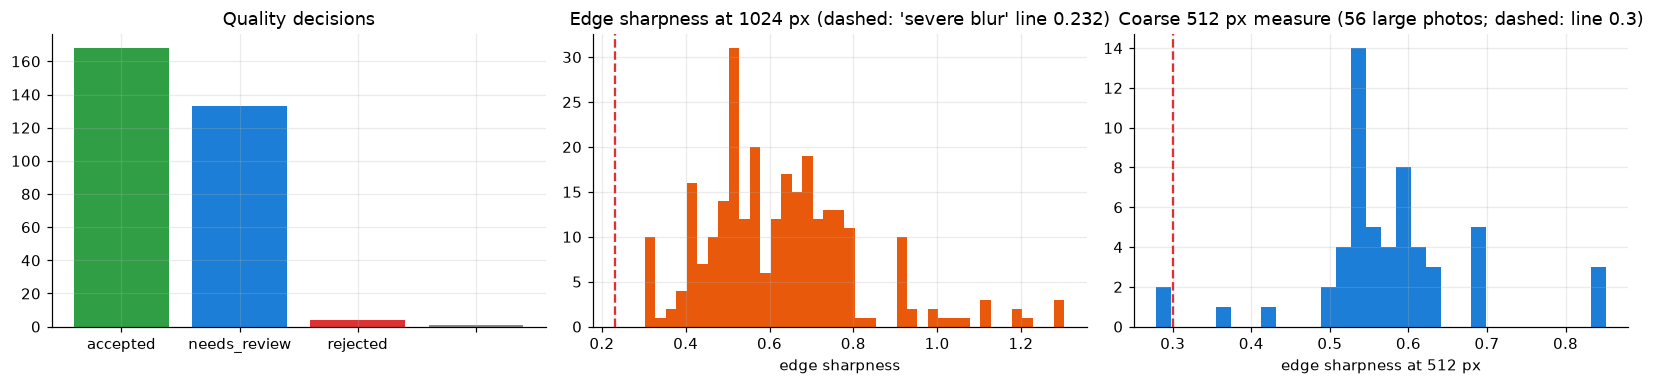

In [2]:
from quality_control.models import ImageQualityDecision
from collections import Counter
rows = list(ImageQualityDecision.objects.values_list("decision", "overall_score", "sharpness_score", "brightness_score", "noise_score", "measurements", "rejection_reasons"))
decisions = Counter(r[0] for r in rows); print("decisions:", dict(decisions)); print("rejection reasons:", dict(Counter(x for r in rows for x in (r[6] or []))))
edge = np.array([ (r[5].get("blur") or {}).get("edge_sharpness") for r in rows if isinstance(r[5], dict) and (r[5].get("blur") or {}).get("edge_sharpness") is not None])
coarse = np.array([ (r[5].get("blur_coarse") or {}).get("edge_sharpness") for r in rows if isinstance(r[5], dict) and (r[5].get("blur_coarse") or {}).get("edge_sharpness") is not None])
overall = {d: [r[1] for r in rows if r[0] == d and r[1] is not None] for d in decisions}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].bar(list(decisions), list(decisions.values()), color=[COLORS["good"], COLORS["baseline"], COLORS["bad"], COLORS["input"]][: len(decisions)]); ax[0].set_title("Quality decisions")
ax[1].hist(edge, bins=40, color=COLORS["model"]); ax[1].axvline(0.232, color=COLORS["bad"], ls="--"); ax[1].set_title("Edge sharpness at 1024 px (dashed: 'severe blur' line 0.232)"); ax[1].set_xlabel("edge sharpness")
ax[2].hist(coarse, bins=30, color=COLORS["baseline"]); ax[2].axvline(settings.QUALITY_REJECT_BLUR_COARSE_EDGE, color=COLORS["bad"], ls="--"); ax[2].set_title(f"Coarse 512 px measure ({len(coarse)} large photos; dashed: line {settings.QUALITY_REJECT_BLUR_COARSE_EDGE})"); ax[2].set_xlabel("edge sharpness at 512 px")
fig.tight_layout(); save(fig, "10_quality_thresholds.png")

{'task': 'blur / exposure / noise checks (classical CV)', 'metrics': {'decisions': {'accepted': 168, 'needs_review': 133, 'rejected': 4, '': 1}, 'photographs_scored': 306, 'rejected_for_blur': 2, 'edge_sharpness_median': 0.6109, 'coarse_measured': 56, 'coarse_line': 0.3, 'coarse_within_0.06_above_line': 1, 'mean_overall_score_accepted': 81.3468}, 'note': "thresholds calibrated on the project's own photographs"}
1 large photographs sit within 0.06 above the coarse-blur line: moving the line trades missed blurry photos against refusing sharp low-key ones.


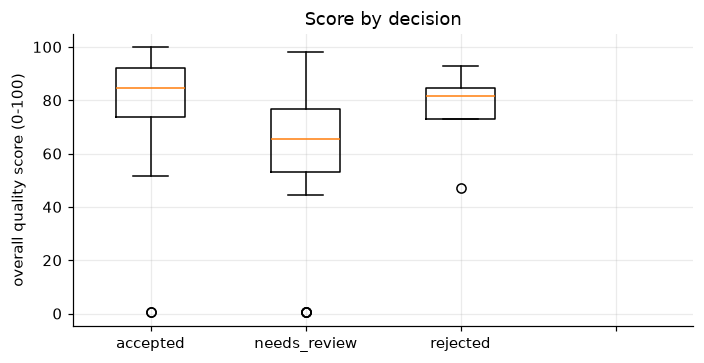

In [3]:
labels = [d for d in overall]; fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.boxplot([overall[d] for d in labels], tick_labels=labels); ax.set_ylabel("overall quality score (0-100)"); ax.set_title("Score by decision"); fig.tight_layout(); save(fig, "10_score_by_decision.png")
rejected_blur = sum(1 for r in rows if "severe_blur" in (r[6] or []))
near = int(((coarse > settings.QUALITY_REJECT_BLUR_COARSE_EDGE) & (coarse < settings.QUALITY_REJECT_BLUR_COARSE_EDGE + 0.06)).sum())
metrics = {"decisions": dict(decisions), "photographs_scored": len(rows), "rejected_for_blur": rejected_blur, "edge_sharpness_median": float(np.median(edge)), "coarse_measured": int(len(coarse)),
           "coarse_line": float(settings.QUALITY_REJECT_BLUR_COARSE_EDGE), "coarse_within_0.06_above_line": near, "mean_overall_score_accepted": float(np.mean(overall.get("accepted", [np.nan])))}
print(scorecard("Quality control", "blur / exposure / noise checks (classical CV)", metrics, "thresholds calibrated on the project's own photographs"))
print(f"{near} large photographs sit within 0.06 above the coarse-blur line: moving the line trades missed blurry photos against refusing sharp low-key ones.")
save_json("10_quality.json", metrics)

## Verdict
The decisions, the score separation between accepted / review / rejected, and the exact position of the two blur lines on the real distribution are shown above. Raising the coarse line catches more soft photographs (such as an intentional motion-blur portrait) but moves it toward sharp, grainy low-key photographs; the line was set from the measured distribution rather than guessed. This part is classical computer vision (Laplacian, gradient and histogram measures), so nothing here was "trained".